# Identitas Praktikum

Nama : Nadira Arzeta
NIM  : 09020625063
kelas: H6B.3

Nama : Shafira Nor Putri Wawan
NIM  : 09020625077
kelas: H6B.3

# Judul Praktikum

Analisis Clustering Negara Berdasarkan Indikator Sosial, Ekonomi, dan Kesehatan Menggunakan Algoritma K-Means dan Hierarchical Clustering

# Rumusan Masalah

1. Bagaimana karakteristik sosial, ekonomi, dan kesehatan dari 167 negara?
2. Bagaimana hasil pengelompokan negara menggunakan K-Means?
3. Bagaimana hasil pengelompokan negara menggunakan Agglomerative Clustering?
4. Algoritma mana yang menghasilkan kualitas clustering terbaik?
5. Bagaimana karakteristik setiap kelompok negara yang terbentuk?

# praktikum 1 - Business Understanding

## Problem Statement (Pernyataan Masalah)

ELP International memiliki dana bantuan sebesar $10 juta, tetapi CEO menghadapi tantangan dalam menentukan negara yang paling membutuhkan bantuan karena setiap negara memiliki kondisi sosial, ekonomi, dan kesehatan yang berbeda. Diperlukan analisis untuk mengelompokkan negara berdasarkan karakteristik dan tingkat kebutuhannya agar alokasi bantuan lebih terarah dan tepat sasaran.

## Business Objective

Menghasilkan rekomendasi pengelompokan negara berdasarkan tingkat kebutuhan sosial, ekonomi, dan kesehatan sebagai bahan pertimbangan CEO dalam menentukan prioritas penerima bantuan sehingga dana $10 juta dapat dialokasikan secara strategis, efektif, dan tepat sasaran.

## Data Science Objective

Menerapkan algoritma K-Means dan Agglomerative Clustering untuk mengelompokkan negara berdasarkan sembilan indikator sosial, ekonomi, dan kesehatan. Menganalisis karakteristik setiap cluster dan membandingkan performa kedua algoritma menggunakan Silhouette Score, Davies-Bouldin Index, dan Calinski-Harabasz Score untuk memperoleh kualitas pengelompokan terbaik sebagai dasar rekomendasi prioritas bantuan.

# Praktikum 2 - Data Understanding

## Import library

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Library preprocessing
from sklearn.preprocessing import PowerTransformer, StandardScaler

# Library clustering
from sklearn.cluster import KMeans, AgglomerativeClustering

# Library evaluasi
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

print("Library berhasil diimport!")

Library berhasil diimport!


## Upload dataset

In [40]:
import pandas as pd

url = "https://raw.githubusercontent.com/tejj2509/Project-Clustering-On-Country-Data/main/Country-data.csv"

df = pd.read_csv(url)

print("Dataset berhasil dimuat!")
print("Ukuran dataset:", df.shape)

display(df.head())

Dataset berhasil dimuat!
Ukuran dataset: (167, 10)


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


## Melihat data

In [41]:
# Melihat 5 data pertama
display(df.head())

# Melihat ukuran dataset
print("Ukuran dataset:", df.shape)

# Informasi dataset
df.info()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


Ukuran dataset: (167, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB


## Statistik deskriptif

In [9]:
display(df.describe())

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


## Memeriksa missing value

In [10]:
print("Missing Values:")
print(df.isnull().sum())

print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

Missing Values:
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

Jumlah Data Duplikat:
0


## Interpretasi

### 1. Interpretasi dataset

Berdasarkan dataset Country Data yang digunakan, diperoleh informasi berikut:

Informasi	Hasil
- Jumlah data	167 negara
- Jumlah kolom	10 kolom
- Kolom kategorikal	1 (country)
- Kolom numerik	9
- Jenis pembelajaran	Unsupervised Learning
- Jenis permasalahan	Clustering


### 2. Interpretasi setiap variabel

Variabel dan Interpretasi
- country =	Identitas atau nama negara.
- child_mort =	Tingkat kematian anak di bawah usia 5 tahun per 1.000 kelahiran hidup.
- exports = 	Persentase ekspor barang dan jasa terhadap GDP.
- health = Persentase pengeluaran kesehatan terhadap GDP.
- imports = 	Persentase impor barang dan jasa terhadap GDP.
- income = 	Pendapatan bersih per orang.
- inflation	= Tingkat inflasi atau pertumbuhan harga.
- life_expec =	Rata-rata harapan hidup penduduk.
- total_fer	= Rata-rata jumlah anak yang dilahirkan setiap perempuan.
- gdpp	= GDP per kapita.

### 3. Interpretasi hasil Data Understanding

A. Melihat lima data pertama (df.head())
Interpretasi:

Berdasarkan lima data pertama, dataset menunjukkan bahwa setiap negara memiliki nilai indikator sosial, ekonomi, dan kesehatan yang berbeda-beda. Perbedaan tersebut memperlihatkan adanya variasi kondisi antarnegara sehingga dataset berpotensi digunakan untuk proses clustering.

B. Melihat ukuran dataset (df.shape)
Interpretasi:

Dataset memiliki 167 baris dan 10 kolom. Jumlah baris menunjukkan terdapat 167 negara yang dianalisis, sedangkan 10 kolom terdiri dari satu variabel identitas negara dan sembilan variabel numerik.

C. Informasi tipe data (df.info())
Interpretasi:

Dataset memiliki kombinasi tipe data kategorikal dan numerik. Variabel country bertipe object karena berisi nama negara, sedangkan sembilan variabel lainnya bertipe numerik.

Variabel numerik dapat digunakan sebagai fitur dalam proses clustering, sementara variabel country digunakan sebagai identitas untuk mengetahui negara yang masuk ke dalam setiap cluster.

D. Statistik deskriptif (df.describe())
Berdasarkan statistik deskriptif, terlihat bahwa setiap variabel memiliki rentang nilai yang berbeda. Variabel income dan gdpp memiliki perbedaan nilai yang cukup besar antara minimum dan maksimum.

Sementara itu, variabel child_mort dan total_fer juga menunjukkan variasi kondisi kesehatan dan demografi antarnegara.

E. Pemeriksaan missing value dan duplikasi
Interpretasi:

Pemeriksaan missing value dilakukan untuk mengetahui apakah terdapat data kosong pada setiap variabel. Sementara itu, pemeriksaan duplikasi bertujuan untuk memastikan tidak terdapat baris data yang tercatat lebih dari satu kali.

hasil pemeriksaan menunjukkan nol missing value dan nol duplikasi, berarti dataset memiliki kelengkapan data yang baik dan tidak memerlukan penanganan khusus untuk kedua permasalahan tersebut.



## EDA Pola

### Grafik 1. 10 Negara dengan GDP per Kapita Tertinggi

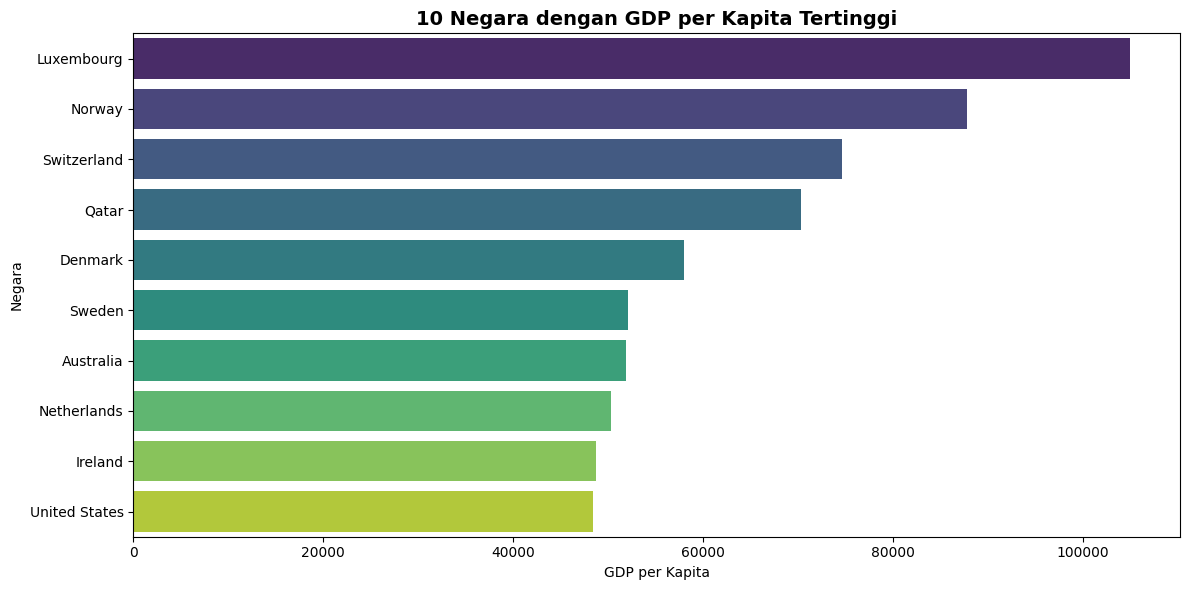

In [11]:
# Mengambil 10 negara dengan GDP per kapita tertinggi
top_gdp = df.nlargest(10, 'gdpp')

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_gdp,
    x='gdpp',
    y='country',
    palette='viridis'
)

plt.title('10 Negara dengan GDP per Kapita Tertinggi',
          fontsize=14, fontweight='bold')
plt.xlabel('GDP per Kapita')
plt.ylabel('Negara')
plt.tight_layout()
plt.show()

### Grafik 2. 10 Negara dengan Angka Kematian Anak Tertinggi

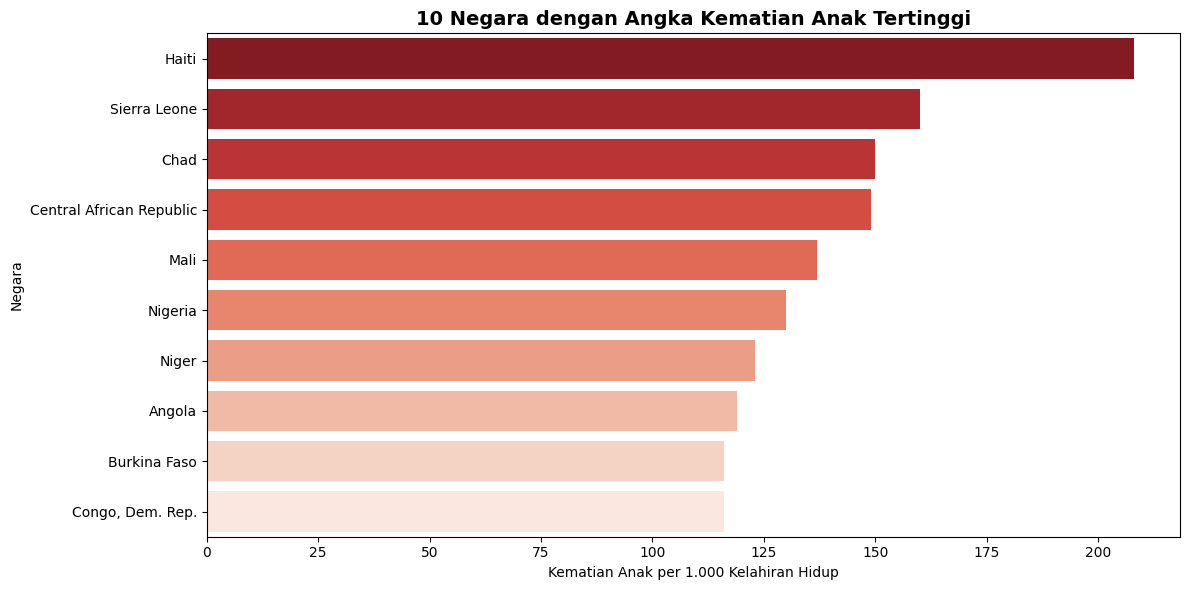

In [12]:
# Mengambil 10 negara dengan angka kematian anak tertinggi
top_mort = df.nlargest(10, 'child_mort')

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_mort,
    x='child_mort',
    y='country',
    palette='Reds_r'
)

plt.title('10 Negara dengan Angka Kematian Anak Tertinggi',
          fontsize=14, fontweight='bold')
plt.xlabel('Kematian Anak per 1.000 Kelahiran Hidup')
plt.ylabel('Negara')
plt.tight_layout()
plt.show()

### Grafik 3. 10 Negara dengan Harapan Hidup Tertinggi

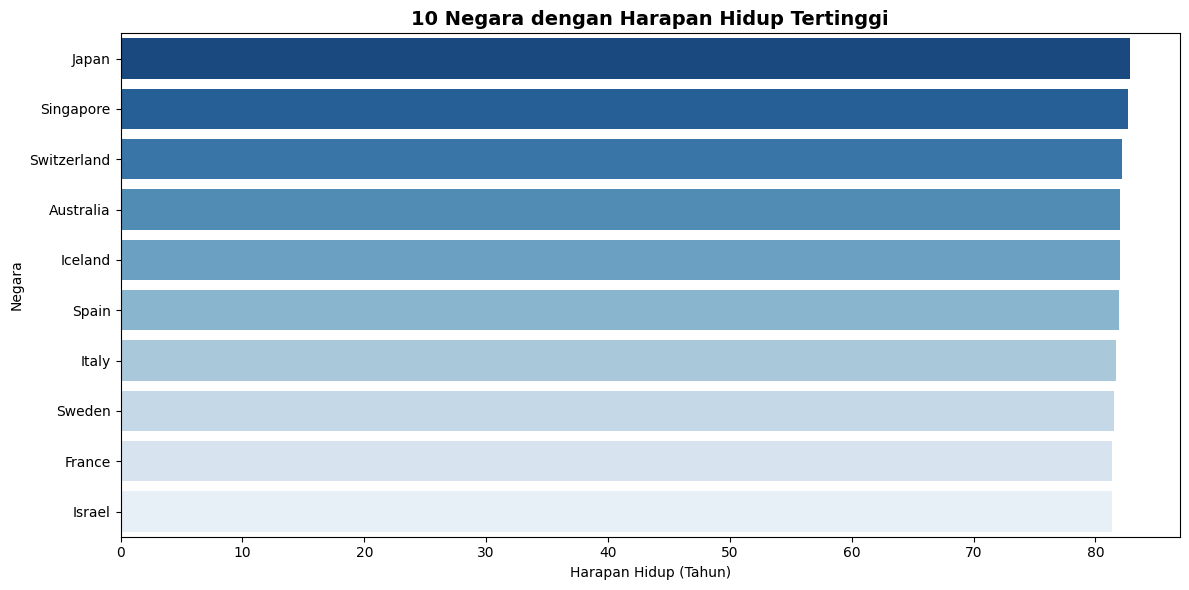

In [13]:
# Mengambil 10 negara dengan harapan hidup tertinggi
top_life = df.nlargest(10, 'life_expec')

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_life,
    x='life_expec',
    y='country',
    palette='Blues_r'
)

plt.title('10 Negara dengan Harapan Hidup Tertinggi',
          fontsize=14, fontweight='bold')
plt.xlabel('Harapan Hidup (Tahun)')
plt.ylabel('Negara')
plt.tight_layout()
plt.show()

# Praktikum 3 - Data Preparation

## Data Cleaning

In [14]:
# Menghapus data duplikat
df = df.drop_duplicates()

# Mengisi missing value numerik dengan median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Mengisi missing value kategorikal
for col in df.select_dtypes(exclude=np.number).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Data setelah cleaning:", df.shape)
print("Total missing value:", df.isnull().sum().sum())

Data setelah cleaning: (167, 10)
Total missing value: 0


## Memisahkan fitur dan identitas negara

In [15]:
# Kolom identitas negara
country = df['country']

# Mengambil fitur numerik
X = df.drop(columns=['country'])

print("Fitur yang digunakan:")
print(X.columns.tolist())

print("\nJumlah fitur:", X.shape[1])

Fitur yang digunakan:
['child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']

Jumlah fitur: 9


## Transformasi data

In [16]:
transformer = PowerTransformer(method='yeo-johnson')

X_transformed = transformer.fit_transform(X)

X_transformed = pd.DataFrame(
    X_transformed,
    columns=X.columns
)

display(X_transformed.head())

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.266699,-1.671164,0.402266,0.064586,-1.368935,0.459416,-1.526455,1.544053,-1.462273
1,-0.220994,-0.380078,0.034400,0.226872,0.012538,-0.154659,0.621738,-0.992833,-0.121133
2,0.217834,0.105605,-0.991140,-0.610572,0.232275,1.059790,0.652698,0.313175,-0.063195
3,1.506186,0.943040,-1.727642,-0.026621,-0.408251,1.512843,-1.239045,1.623128,-0.219666
4,-0.637380,0.385850,-0.166030,0.641531,0.572583,-0.723442,0.699553,-0.368063,0.609228


## Normalisasi data

In [17]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_transformed)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Normalisasi berhasil!")

display(X_scaled.head())

Normalisasi berhasil!


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.266699,-1.671164,0.402266,0.064586,-1.368935,0.459416,-1.526455,1.544053,-1.462273
1,-0.220994,-0.380078,0.034400,0.226872,0.012538,-0.154659,0.621738,-0.992833,-0.121133
2,0.217834,0.105605,-0.991140,-0.610572,0.232275,1.059790,0.652698,0.313175,-0.063195
3,1.506186,0.943040,-1.727642,-0.026621,-0.408251,1.512843,-1.239045,1.623128,-0.219666
4,-0.637380,0.385850,-0.166030,0.641531,0.572583,-0.723442,0.699553,-0.368063,0.609228


## Interpretasi

### 1. Interpretasi pemisahan fitur

Interpretasi:

Pada tahap ini dilakukan pemisahan antara variabel identitas negara dan variabel yang digunakan sebagai fitur dalam proses clustering.

Variabel country tidak disertakan dalam proses pemodelan karena hanya berfungsi sebagai identitas atau penanda nama negara. Sementara itu, sembilan variabel numerik dipilih sebagai fitur karena masing-masing memiliki informasi yang menggambarkan kondisi sosial, ekonomi, dan kesehatan suatu negara.

Sembilan fitur yang digunakan meliputi:
- child_mort: Menggambarkan tingkat kematian anak.
- exports: Menggambarkan persentase ekspor terhadap GDP.
- health: Menggambarkan pengeluaran kesehatan terhadap GDP.
- imports: Menggambarkan persentase impor terhadap GDP.
- income: Menggambarkan pendapatan per kapita.
- inflation: Menggambarkan tingkat inflasi.
- life_expec: Menggambarkan angka harapan hidup.
- total_fer: Menggambarkan tingkat fertilitas.
- gdpp: Menggambarkan GDP per kapita.

### 2. Interpretasi transformasi data

Interpretasi:

Pada tahap ini dilakukan transformasi data menggunakan metode PowerTransformer dengan teknik Yeo-Johnson. Transformasi ini bertujuan untuk mengurangi kemencengan distribusi data (skewness) agar distribusi setiap variabel menjadi lebih mendekati normal.

Transformasi diperlukan karena beberapa variabel ekonomi dan sosial dalam dataset memiliki rentang nilai yang cukup jauh dan kemungkinan distribusi yang tidak merata.

Metode Yeo-Johnson dipilih karena mampu menangani data yang memiliki nilai positif, nol, maupun negatif.

Berdasarkan hasil transformasi, nilai setiap variabel mengalami perubahan skala dan distribusi. Nilai positif menunjukkan posisi data yang relatif berada di atas pusat distribusi hasil transformasi, sedangkan nilai negatif menunjukkan posisi yang relatif berada di bawah pusat distribusi tersebut.

Perubahan ini membantu mengurangi pengaruh kemencengan distribusi sebelum data digunakan dalam proses normalisasi dan clustering.

Kesimpulan: Transformasi data dilakukan untuk memperbaiki karakteristik distribusi setiap variabel sehingga data menjadi lebih siap untuk diproses pada tahap pemodelan clustering.

### 3. Interpretasi normalisasi data

Pada tahap ini dilakukan normalisasi menggunakan metode StandardScaler. Tujuannya adalah menyamakan skala seluruh variabel sehingga setiap fitur memiliki rata-rata mendekati 0 dan standar deviasi mendekati 1.

Normalisasi diperlukan karena setiap variabel dalam dataset memiliki satuan dan rentang nilai yang berbeda. Misalnya, variabel income dan gdpp memiliki nilai yang jauh lebih besar dibandingkan variabel total_fer atau inflation.

Kesimpulan: Normalisasi berhasil menyamakan skala seluruh fitur sehingga setiap variabel dapat berkontribusi secara lebih seimbang dalam perhitungan jarak pada algoritma K-Means dan Hierarchical

# Tahap 4 - Modeling

## 4.1 Modeling menggunakan K-Means

### Menentukan jumlah cluster K-Means




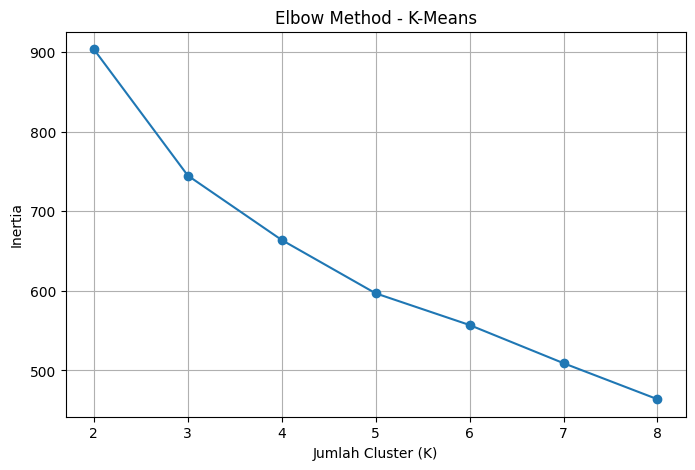

In [18]:
# Pengujian jumlah cluster K-Means

inertia_values = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia_values.append(model.inertia_)

# Visualisasi Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    inertia_values,
    marker='o'
)

plt.title('Elbow Method - K-Means')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.xticks(range(2, 9))
plt.grid()
plt.show()

### Interpretasi Elbow Method

Elbow Method digunakan untuk menentukan jumlah cluster yang optimal pada algoritma K-Means dengan mengamati perubahan nilai inertia dari jumlah cluster 2 hingga 8.

Nilai inertia menunjukkan jumlah kuadrat jarak antara setiap data dengan pusat cluster (centroid). Semakin kecil nilai inertia, semakin dekat anggota cluster dengan pusat kelompoknya.

Melalui grafik Elbow Method, dapat diamati titik ketika penurunan inertia mulai melambat. Titik tersebut menjadi salah satu pertimbangan dalam menentukan jumlah cluster yang sesuai.



### Evaluasi seluruh jumlah cluster K-Means

In [19]:
hasil_kmeans = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    hasil_kmeans.append({
        'Jumlah Cluster': k,
        'Silhouette Score': silhouette_score(
            X_scaled, labels
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            X_scaled, labels
        ),
        'Calinski-Harabasz Score': calinski_harabasz_score(
            X_scaled, labels
        )
    })

evaluasi_kmeans = pd.DataFrame(hasil_kmeans)

display(evaluasi_kmeans.round(4))

,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,0.3372,1.1323,109.5408
1,3,0.2458,1.3837,83.4876
2,4,0.2219,1.4270,68.6872
3,5,0.2226,1.4620,61.4869
4,6,0.1972,1.4021,54.6775
5,7,0.2366,1.3123,52.0521
6,8,0.2369,1.2422,50.8745


### Interpretasi Evaluasi cluster K-Means

Pengujian dilakukan dengan mencoba jumlah cluster dari 2 hingga 8. Setiap percobaan dievaluasi menggunakan tiga metrik, yaitu Silhouette Score, Davies-Bouldin Index, dan Calinski-Harabasz Score.

Ketiga metrik tersebut digunakan untuk mengetahui kualitas pengelompokan berdasarkan tingkat kemiripan anggota dalam cluster dan tingkat pemisahan antarcluster.

Jumlah cluster terbaik ditentukan melalui peringkat gabungan ketiga metrik, dengan mempertimbangkan nilai Silhouette dan Calinski-Harabasz tertinggi serta Davies-Bouldin terendah.

### Menentukan jumlah cluster terbaik K-Means

In [20]:
# Membuat peringkat setiap metrik

evaluasi_kmeans['Rank Silhouette'] = (
    evaluasi_kmeans['Silhouette Score']
    .rank(ascending=False)
)

evaluasi_kmeans['Rank DBI'] = (
    evaluasi_kmeans['Davies-Bouldin Index']
    .rank(ascending=True)
)

evaluasi_kmeans['Rank Calinski'] = (
    evaluasi_kmeans['Calinski-Harabasz Score']
    .rank(ascending=False)
)

# Menghitung total peringkat
evaluasi_kmeans['Total Rank'] = (
    evaluasi_kmeans['Rank Silhouette'] +
    evaluasi_kmeans['Rank DBI'] +
    evaluasi_kmeans['Rank Calinski']
)

# Mengurutkan berdasarkan total ranking terkecil
evaluasi_kmeans = evaluasi_kmeans.sort_values(
    'Total Rank'
)

display(evaluasi_kmeans.round(4))

# Menentukan K terbaik
best_kmeans = int(
    evaluasi_kmeans.iloc[0]['Jumlah Cluster']
)

print("Jumlah cluster terbaik K-Means:", best_kmeans)

,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Rank Silhouette,Rank DBI,Rank Calinski,Total Rank
0,2,0.3372,1.1323,109.5408,1.0,1.0,1.0,3.0
1,3,0.2458,1.3837,83.4876,2.0,4.0,2.0,8.0
6,8,0.2369,1.2422,50.8745,3.0,2.0,7.0,12.0
5,7,0.2366,1.3123,52.0521,4.0,3.0,6.0,13.0
2,4,0.2219,1.4270,68.6872,6.0,6.0,3.0,15.0
3,5,0.2226,1.4620,61.4869,5.0,7.0,4.0,16.0
4,6,0.1972,1.4021,54.6775,7.0,5.0,5.0,17.0


Jumlah cluster terbaik K-Means: 2


Kenapa menggunakan ranking?

Karena ketiga metrik memiliki arah penilaian yang berbeda. Dengan ranking, kita dapat mempertimbangkan ketiganya secara bersamaan dengan bobot yang sama.

Jumlah rangking terkecil menjadi pilihan terbaik berdasarkan ketiga metrik tersebut.




### Membuat model K-Means terbaik

In [21]:
kmeans_final = KMeans(
    n_clusters=best_kmeans,
    random_state=42,
    n_init=10
)

label_kmeans = kmeans_final.fit_predict(X_scaled)

print("Model K-Means berhasil dibuat!")
print("Jumlah cluster:", best_kmeans)

# Evaluasi model final
print("Silhouette Score:",
      silhouette_score(X_scaled, label_kmeans))

print("Davies-Bouldin Index:",
      davies_bouldin_score(X_scaled, label_kmeans))

print("Calinski-Harabasz Score:",
      calinski_harabasz_score(X_scaled, label_kmeans))

Model K-Means berhasil dibuat!
Jumlah cluster: 2
Silhouette Score: 0.33716089816523753
Davies-Bouldin Index: 1.1323206886068398
Calinski-Harabasz Score: 109.5408050611017


### Interpretasi hasil model K-Means terbaik

Setelah memperoleh jumlah cluster terbaik, model K-Means dibangun kembali menggunakan jumlah cluster tersebut.

Model kemudian menghasilkan pengelompokan negara berdasarkan kemiripan sembilan indikator sosial, ekonomi, dan kesehatan.

Setiap negara akan dimasukkan ke dalam salah satu cluster berdasarkan kedekatannya dengan centroid. Negara yang berada dalam cluster yang sama memiliki karakteristik yang relatif serupa berdasarkan fitur yang digunakan.

### Visualisasi hasil K-Means

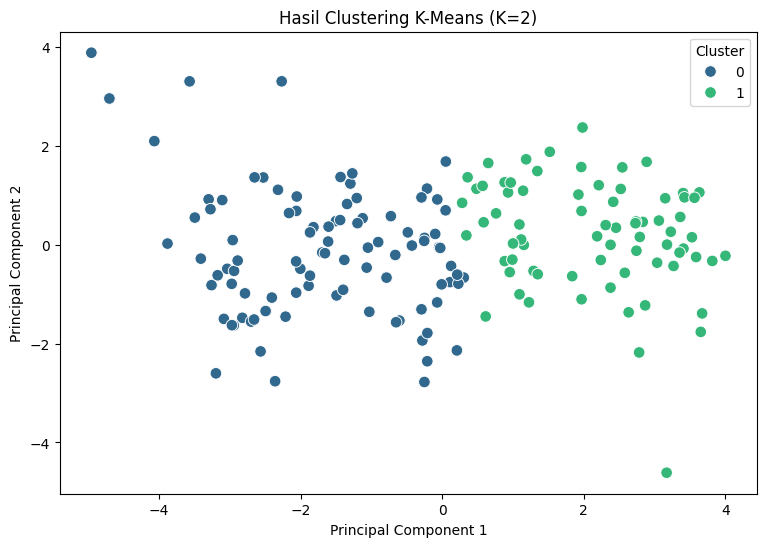

In [22]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=label_kmeans,
    palette='viridis',
    s=70
)

plt.title(
    f'Hasil Clustering K-Means (K={best_kmeans})'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

### Interpretasi hasil K-Means menggunakan PCA

Pemodelan K-Means dilakukan dengan menguji jumlah cluster dari 2 hingga 8. Penentuan jumlah cluster terbaik dilakukan melalui Elbow Method dan evaluasi. menggunakan Silhouette Score, Davies-Bouldin Index, serta Calinski-Harabasz Score.

Berdasarkan ketiga metrik tersebut, dipilih jumlah cluster dengan total peringkat terbaik. Selanjutnya, model K-Means dibangun kembali menggunakan jumlah cluster terpilih untuk memperoleh hasil pengelompokan negara.

## 4.2 Modeling menggunakan Hierarchical Clustering

### Membuat dendrogram

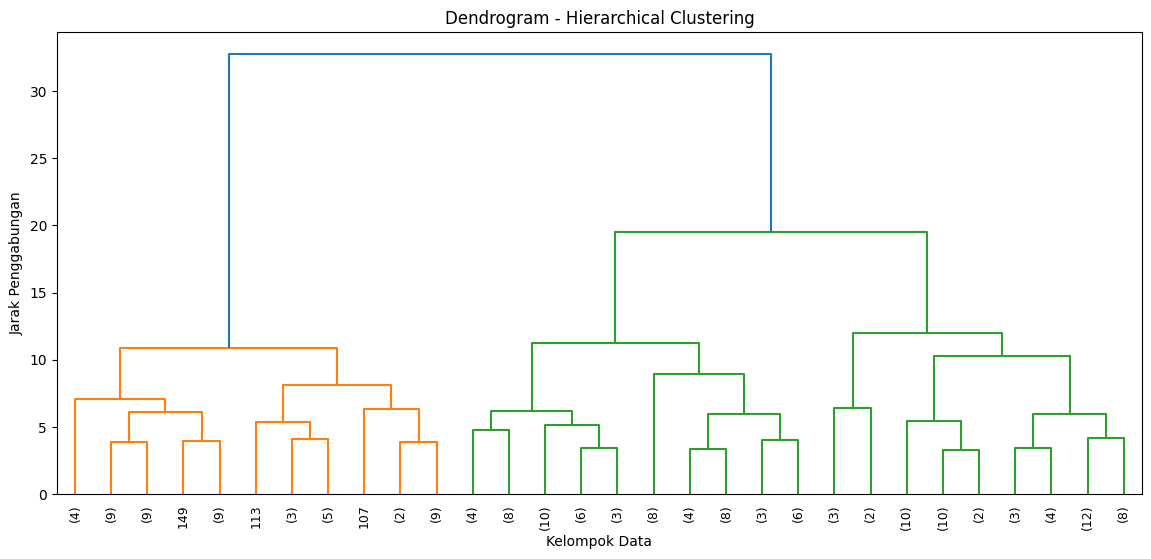

In [23]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Membuat linkage matrix
Z = linkage(
    X_scaled,
    method='ward'
)

# Visualisasi dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title('Dendrogram - Hierarchical Clustering')
plt.xlabel('Kelompok Data')
plt.ylabel('Jarak Penggabungan')
plt.show()

### Interpretasi Dendrogram

Dendrogram menggambarkan proses penggabungan kelompok negara berdasarkan tingkat kemiripan karakteristiknya. Semakin tinggi jarak penggabungan, semakin besar perbedaan antar kelompok yang digabungkan.

Dendrogram digunakan sebagai visualisasi pendukung, sedangkan penentuan jumlah cluster akan diuji menggunakan tiga metrik evaluasi.

### Pengujian jumlah cluster Hierarchical

In [24]:
hasil_hierarchical = []

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)

    hasil_hierarchical.append({
        'Jumlah Cluster': k,
        'Silhouette Score': silhouette_score(
            X_scaled, labels
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            X_scaled, labels
        ),
        'Calinski-Harabasz Score': calinski_harabasz_score(
            X_scaled, labels
        )
    })

evaluasi_hierarchical = pd.DataFrame(
    hasil_hierarchical
)

display(evaluasi_hierarchical.round(4))

,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,0.3178,1.1301,91.4753
1,3,0.2217,1.4831,76.6752
2,4,0.2283,1.3379,61.5179
3,5,0.2068,1.4223,54.4203
4,6,0.2063,1.5170,50.9445
5,7,0.1886,1.4873,49.0310
6,8,0.2043,1.4200,47.0432


### Menentukan jumlah cluster terbaik Hierarchical

In [25]:
# Ranking Silhouette
evaluasi_hierarchical['Rank Silhouette'] = (
    evaluasi_hierarchical['Silhouette Score']
    .rank(ascending=False)
)

# Ranking DBI
evaluasi_hierarchical['Rank DBI'] = (
    evaluasi_hierarchical['Davies-Bouldin Index']
    .rank(ascending=True)
)

# Ranking Calinski
evaluasi_hierarchical['Rank Calinski'] = (
    evaluasi_hierarchical['Calinski-Harabasz Score']
    .rank(ascending=False)
)

# Total ranking
evaluasi_hierarchical['Total Rank'] = (
    evaluasi_hierarchical['Rank Silhouette'] +
    evaluasi_hierarchical['Rank DBI'] +
    evaluasi_hierarchical['Rank Calinski']
)

evaluasi_hierarchical = evaluasi_hierarchical.sort_values(
    'Total Rank'
)

display(evaluasi_hierarchical.round(4))

# Menentukan cluster terbaik
best_k_hierarchical = int(
    evaluasi_hierarchical.iloc[0]['Jumlah Cluster']
)

print(
    "Jumlah cluster terbaik Hierarchical:",
    best_k_hierarchical
)

,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Rank Silhouette,Rank DBI,Rank Calinski,Total Rank
0,2,0.3178,1.1301,91.4753,1.0,1.0,1.0,3.0
2,4,0.2283,1.3379,61.5179,2.0,2.0,3.0,7.0
1,3,0.2217,1.4831,76.6752,3.0,5.0,2.0,10.0
3,5,0.2068,1.4223,54.4203,4.0,4.0,4.0,12.0
6,8,0.2043,1.4200,47.0432,6.0,3.0,7.0,16.0
4,6,0.2063,1.5170,50.9445,5.0,7.0,5.0,17.0
5,7,0.1886,1.4873,49.0310,7.0,6.0,6.0,19.0


Jumlah cluster terbaik Hierarchical: 2


### Evaluasi jumlah cluster Hierarchical

Pada tahap ini dilakukan pengujian jumlah cluster dari 2 hingga 8 menggunakan algoritma Agglomerative Clustering.

Setiap jumlah cluster dievaluasi menggunakan Silhouette Score, Davies-Bouldin Index, dan Calinski-Harabasz Score.

Hasil pengujian digunakan untuk mengetahui jumlah cluster yang mampu menghasilkan pengelompokan negara dengan kualitas terbaik.

Penentuan jumlah cluster dilakukan melalui peringkat gabungan ketiga metrik, sehingga tidak hanya bergantung pada satu indikator evaluasi.

### Membuat model Hierarchical terbaik

In [26]:
hierarchical_final = AgglomerativeClustering(
    n_clusters=best_k_hierarchical,
    linkage='ward'
)

label_hierarchical = hierarchical_final.fit_predict(
    X_scaled
)

print("Model Hierarchical berhasil dibuat!")
print("Jumlah cluster:", best_k_hierarchical)

print("Silhouette Score:",
      silhouette_score(X_scaled, label_hierarchical))

print("Davies-Bouldin Index:",
      davies_bouldin_score(X_scaled, label_hierarchical))

print("Calinski-Harabasz Score:",
      calinski_harabasz_score(X_scaled, label_hierarchical))

Model Hierarchical berhasil dibuat!
Jumlah cluster: 2
Silhouette Score: 0.3177649002914756
Davies-Bouldin Index: 1.1300889878589573
Calinski-Harabasz Score: 91.47527548546073


### Interpretasi hasil model Hierarchical terbaik

Setelah jumlah cluster terbaik diperoleh, model Agglomerative Clustering dibangun kembali menggunakan jumlah cluster tersebut dan metode linkage Ward.

Model menghasilkan kelompok negara berdasarkan tingkat kemiripan karakteristik sosial, ekonomi, dan kesehatan.

Berbeda dengan K-Means yang menggunakan centroid sebagai pusat kelompok, Hierarchical Clustering membentuk kelompok melalui proses penggabungan data secara bertahap.

Hasil pengelompokan ini dapat digunakan untuk mengetahui negara-negara yang memiliki karakteristik serupa berdasarkan sembilan indikator yang digunakan.

### Visualisasi hasil Hierarchical

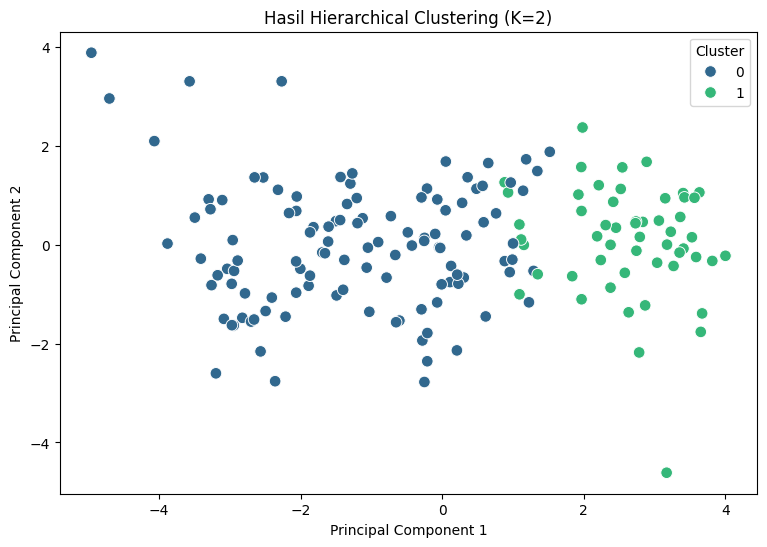

In [27]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=label_hierarchical,
    palette='viridis',
    s=70
)

plt.title(
    f'Hasil Hierarchical Clustering '
    f'(K={best_k_hierarchical})'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

### Interpretasi visualisasi hasil hierarchical menggunakan PCA

Visualisasi PCA digunakan untuk memperlihatkan hasil pengelompokan Hierarchical Clustering dalam dua dimensi.

Setiap titik merepresentasikan satu negara, sedangkan warna menunjukkan cluster yang dihasilkan oleh algoritma.

Grafik ini membantu mengamati pola persebaran negara dan melihat apakah kelompok yang terbentuk memiliki pemisahan yang cukup jelas.

Visualisasi ini juga dapat digunakan untuk membandingkan pola pengelompokan Hierarchical dengan K-Means.



### Interpretasi Perbandingan kedua Model

Perbandingan dilakukan untuk mengetahui algoritma yang memberikan kualitas pengelompokan terbaik pada dataset Country Data.

Evaluasi menggunakan tiga metrik, yaitu:
| **Metrik** | **Kriteria Terbaik** |
|---|---|
| Silhouette Score | Nilai tertinggi |
| Davies-Bouldin Index | Nilai terendah |
| Calinski-Harabasz Score | Nilai tertinggi |


Hasil dari ketiga metrik kemudian digunakan untuk menentukan algoritma yang memiliki kualitas clustering lebih baik.

Algoritma dengan hasil evaluasi yang lebih baik diharapkan mampu menghasilkan kelompok negara yang lebih kompak di dalam cluster dan memiliki pemisahan yang lebih jelas antarcluster.

# Praktikum 5 - Evaluation

### Import library evaluasi

In [28]:
# Import library untuk evaluasi clustering

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("Library evaluasi berhasil diimport!")


Library evaluasi berhasil diimport!


### Memastikan hasil Modeling tersedia

In [29]:

# Memeriksa variabel hasil Modeling

variabel_wajib = [
    'X_scaled',
    'best_kmeans',
    'label_kmeans',
    'best_k_hierarchical',
    'label_hierarchical'
]

for variabel in variabel_wajib:
    if variabel not in globals():
        raise NameError(
            f"Variabel {variabel} belum tersedia. "
            "Jalankan kembali tahap Modeling terlebih dahulu."
        )

print("Semua variabel Modeling tersedia!")
print("Jumlah data:", len(X_scaled))
print("Jumlah cluster K-Means:", best_kmeans)
print("Jumlah cluster Hierarchical:", best_k_hierarchical)


Semua variabel Modeling tersedia!
Jumlah data: 167
Jumlah cluster K-Means: 2
Jumlah cluster Hierarchical: 2


### Evaluasi K-Means

In [30]:

# Evaluasi K-Means

sil_kmeans = silhouette_score(
    X_scaled, label_kmeans
)

dbi_kmeans = davies_bouldin_score(
    X_scaled, label_kmeans
)

chi_kmeans = calinski_harabasz_score(
    X_scaled, label_kmeans
)

print("HASIL EVALUASI K-MEANS")
print("=" * 40)
print("Jumlah Cluster:", best_kmeans)
print("Silhouette Score:", round(sil_kmeans, 4))
print("Davies-Bouldin Index:", round(dbi_kmeans, 4))
print("Calinski-Harabasz Score:", round(chi_kmeans, 4))


HASIL EVALUASI K-MEANS
Jumlah Cluster: 2
Silhouette Score: 0.3372
Davies-Bouldin Index: 1.1323
Calinski-Harabasz Score: 109.5408


### Evaluasi Hierarchical Clustering

In [31]:

# Evaluasi Hierarchical Clustering

sil_hierarchical = silhouette_score(
    X_scaled, label_hierarchical
)

dbi_hierarchical = davies_bouldin_score(
    X_scaled, label_hierarchical
)

chi_hierarchical = calinski_harabasz_score(
    X_scaled, label_hierarchical
)

print("HASIL EVALUASI HIERARCHICAL CLUSTERING")
print("=" * 40)
print("Jumlah Cluster:", best_k_hierarchical)
print("Silhouette Score:", round(sil_hierarchical, 4))
print("Davies-Bouldin Index:", round(dbi_hierarchical, 4))
print("Calinski-Harabasz Score:", round(chi_hierarchical, 4))


HASIL EVALUASI HIERARCHICAL CLUSTERING
Jumlah Cluster: 2
Silhouette Score: 0.3178
Davies-Bouldin Index: 1.1301
Calinski-Harabasz Score: 91.4753


### Membuat tabel perbandingan kedua algoritma

In [32]:

# Membuat tabel perbandingan hasil evaluasi

hasil_evaluasi = pd.DataFrame({
    'Algoritma': [
        'K-Means',
        'Hierarchical Clustering'
    ],
    'Jumlah Cluster': [
        best_kmeans,
        best_k_hierarchical
    ],
    'Silhouette Score': [
        sil_kmeans,
        sil_hierarchical
    ],
    'Davies-Bouldin Index': [
        dbi_kmeans,
        dbi_hierarchical
    ],
    'Calinski-Harabasz Score': [
        chi_kmeans,
        chi_hierarchical
    ]
})

print("TABEL PERBANDINGAN HASIL EVALUASI")
display(hasil_evaluasi.round(4))


TABEL PERBANDINGAN HASIL EVALUASI


,Algoritma,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,2,0.3372,1.1323,109.5408
1,Hierarchical Clustering,2,0.3178,1.1301,91.4753


### Menentukan algoritma terbaik berdasarkan setiap metrik

In [33]:

# Menentukan algoritma terbaik berdasarkan setiap metrik

best_silhouette = hasil_evaluasi.loc[
    hasil_evaluasi['Silhouette Score'].idxmax(),
    'Algoritma'
]

best_dbi = hasil_evaluasi.loc[
    hasil_evaluasi['Davies-Bouldin Index'].idxmin(),
    'Algoritma'
]

best_calinski = hasil_evaluasi.loc[
    hasil_evaluasi['Calinski-Harabasz Score'].idxmax(),
    'Algoritma'
]

print("HASIL PERBANDINGAN METRIK")
print("=" * 45)

print("Silhouette Score terbaik        :", best_silhouette)
print("Davies-Bouldin Index terbaik    :", best_dbi)
print("Calinski-Harabasz Score terbaik :", best_calinski)


HASIL PERBANDINGAN METRIK
Silhouette Score terbaik        : K-Means
Davies-Bouldin Index terbaik    : Hierarchical Clustering
Calinski-Harabasz Score terbaik : K-Means


## Grafik Silhouette Score

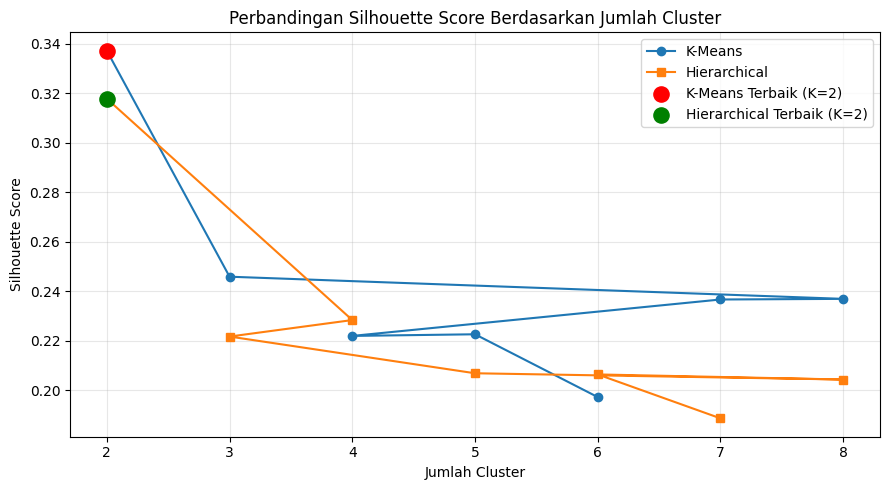

Jumlah Cluster Terbaik:
K-Means: K = 2
Hierarchical: K = 2


In [46]:
plt.figure(figsize=(9, 5))

plt.plot(
    evaluasi_kmeans['Jumlah Cluster'],
    evaluasi_kmeans['Silhouette Score'],
    marker='o',
    label='K-Means'
)

plt.plot(
    evaluasi_hierarchical['Jumlah Cluster'],
    evaluasi_hierarchical['Silhouette Score'],
    marker='s',
    label='Hierarchical'
)

# Menentukan jumlah cluster terbaik
best_kmeans = evaluasi_kmeans.loc[
    evaluasi_kmeans['Silhouette Score'].idxmax()
]

best_hierarchical = evaluasi_hierarchical.loc[
    evaluasi_hierarchical['Silhouette Score'].idxmax()
]

# Memberikan tanda pada titik terbaik
plt.scatter(
    best_kmeans['Jumlah Cluster'],
    best_kmeans['Silhouette Score'],
    color='red',
    s=120,
    zorder=5,
    label=f"K-Means Terbaik (K={int(best_kmeans['Jumlah Cluster'])})"
)

plt.scatter(
    best_hierarchical['Jumlah Cluster'],
    best_hierarchical['Silhouette Score'],
    color='green',
    s=120,
    zorder=5,
    label=f"Hierarchical Terbaik (K={int(best_hierarchical['Jumlah Cluster'])})"
)

plt.xlabel('Jumlah Cluster')
plt.ylabel('Silhouette Score')
plt.title('Perbandingan Silhouette Score Berdasarkan Jumlah Cluster')
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Jumlah Cluster Terbaik:")
print(f"K-Means: K = {int(best_kmeans['Jumlah Cluster'])}")
print(f"Hierarchical: K = {int(best_hierarchical['Jumlah Cluster'])}")




### Visualisasi perbandingan Silhouette Score pada Model Terbaik

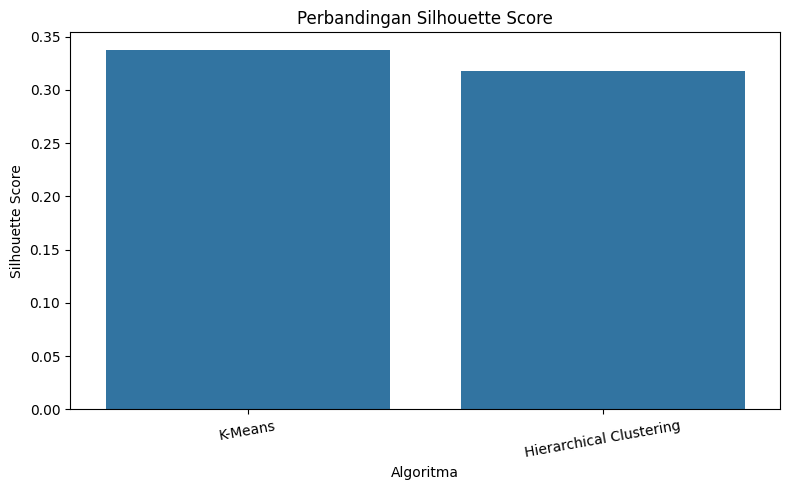

In [35]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=hasil_evaluasi,
    x='Algoritma',
    y='Silhouette Score'
)

plt.title('Perbandingan Silhouette Score')
plt.xlabel('Algoritma')
plt.ylabel('Silhouette Score')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


## Grafik Davies-Bouldin Index

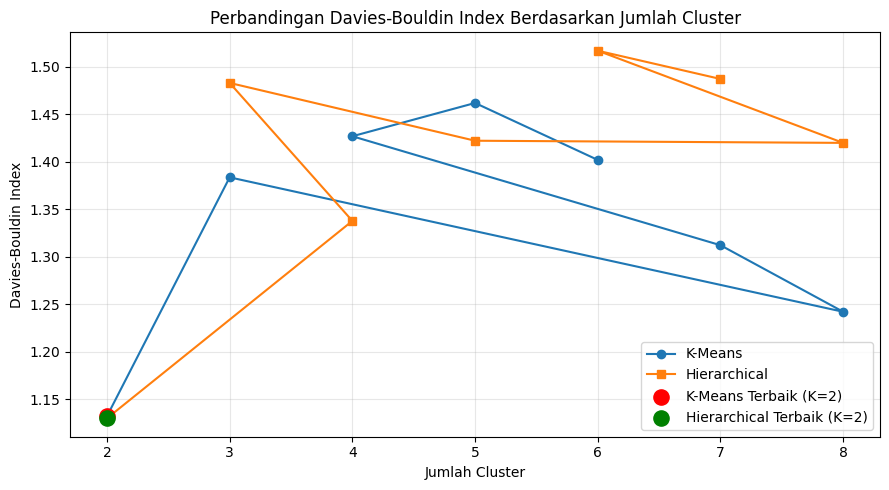

Jumlah Cluster Terbaik Berdasarkan Total Rank:
K-Means: K = 2
Hierarchical: K = 2


In [47]:
plt.figure(figsize=(9, 5))

plt.plot(
    evaluasi_kmeans['Jumlah Cluster'],
    evaluasi_kmeans['Davies-Bouldin Index'],
    marker='o',
    label='K-Means'
)

plt.plot(
    evaluasi_hierarchical['Jumlah Cluster'],
    evaluasi_hierarchical['Davies-Bouldin Index'],
    marker='s',
    label='Hierarchical'
)

# Menentukan jumlah cluster terbaik berdasarkan Total Rank
best_kmeans_dbi = evaluasi_kmeans.loc[
    evaluasi_kmeans['Total Rank'].idxmin()
]

best_hierarchical_dbi = evaluasi_hierarchical.loc[
    evaluasi_hierarchical['Total Rank'].idxmin()
]

# Memberikan tanda pada titik terbaik
plt.scatter(
    best_kmeans_dbi['Jumlah Cluster'],
    best_kmeans_dbi['Davies-Bouldin Index'],
    color='red',
    s=120,
    zorder=5,
    label=f"K-Means Terbaik (K={int(best_kmeans_dbi['Jumlah Cluster'])})"
)

plt.scatter(
    best_hierarchical_dbi['Jumlah Cluster'],
    best_hierarchical_dbi['Davies-Bouldin Index'],
    color='green',
    s=120,
    zorder=5,
    label=f"Hierarchical Terbaik (K={int(best_hierarchical_dbi['Jumlah Cluster'])})"
)

plt.xlabel('Jumlah Cluster')
plt.ylabel('Davies-Bouldin Index')
plt.title('Perbandingan Davies-Bouldin Index Berdasarkan Jumlah Cluster')
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Jumlah Cluster Terbaik Berdasarkan Total Rank:")
print(f"K-Means: K = {int(best_kmeans_dbi['Jumlah Cluster'])}")
print(f"Hierarchical: K = {int(best_hierarchical_dbi['Jumlah Cluster'])}")


### Visualisasi perbandingan Davies-Bouldin Index pada Model Terbaik

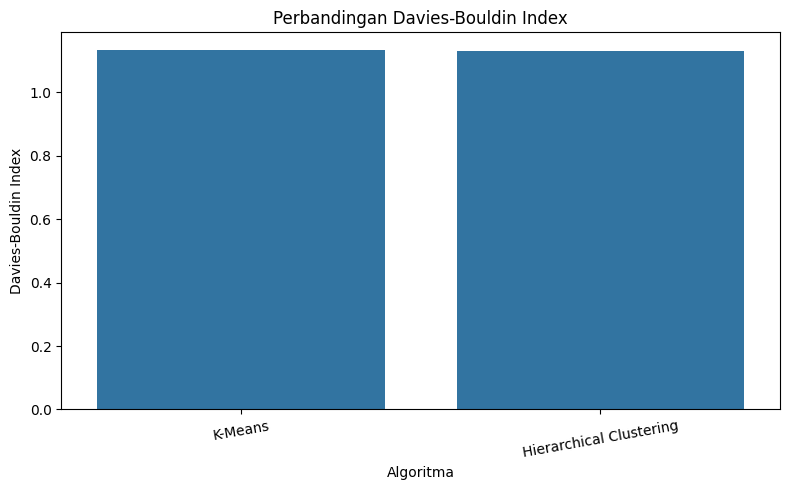

In [36]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=hasil_evaluasi,
    x='Algoritma',
    y='Davies-Bouldin Index'
)

plt.title('Perbandingan Davies-Bouldin Index')
plt.xlabel('Algoritma')
plt.ylabel('Davies-Bouldin Index')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


## Grafik Calinski-Harabasz Score

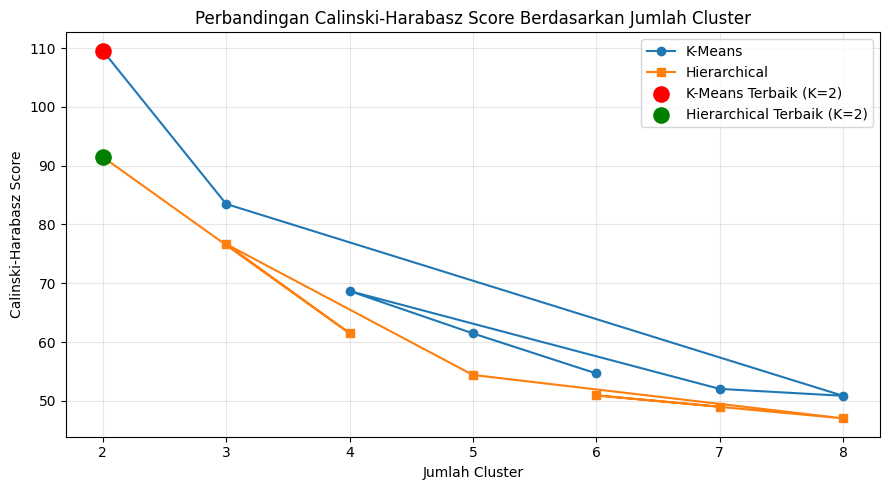

Jumlah Cluster Terbaik Berdasarkan Total Rank:
K-Means: K = 2
Hierarchical: K = 2


In [48]:
plt.figure(figsize=(9, 5))

plt.plot(
    evaluasi_kmeans['Jumlah Cluster'],
    evaluasi_kmeans['Calinski-Harabasz Score'],
    marker='o',
    label='K-Means'
)

plt.plot(
    evaluasi_hierarchical['Jumlah Cluster'],
    evaluasi_hierarchical['Calinski-Harabasz Score'],
    marker='s',
    label='Hierarchical'
)

# Menentukan jumlah cluster terbaik berdasarkan Total Rank
best_kmeans_chs = evaluasi_kmeans.loc[
    evaluasi_kmeans['Total Rank'].idxmin()
]

best_hierarchical_chs = evaluasi_hierarchical.loc[
    evaluasi_hierarchical['Total Rank'].idxmin()
]

# Memberikan tanda pada titik terbaik
plt.scatter(
    best_kmeans_chs['Jumlah Cluster'],
    best_kmeans_chs['Calinski-Harabasz Score'],
    color='red',
    s=120,
    zorder=5,
    label=f"K-Means Terbaik (K={int(best_kmeans_chs['Jumlah Cluster'])})"
)

plt.scatter(
    best_hierarchical_chs['Jumlah Cluster'],
    best_hierarchical_chs['Calinski-Harabasz Score'],
    color='green',
    s=120,
    zorder=5,
    label=f"Hierarchical Terbaik (K={int(best_hierarchical_chs['Jumlah Cluster'])})"
)

plt.xlabel('Jumlah Cluster')
plt.ylabel('Calinski-Harabasz Score')
plt.title('Perbandingan Calinski-Harabasz Score Berdasarkan Jumlah Cluster')
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Jumlah Cluster Terbaik Berdasarkan Total Rank:")
print(f"K-Means: K = {int(best_kmeans_chs['Jumlah Cluster'])}")
print(f"Hierarchical: K = {int(best_hierarchical_chs['Jumlah Cluster'])}")


### Visualisasi perbandingan Calinski-Harabasz Score pada Model Terbaik


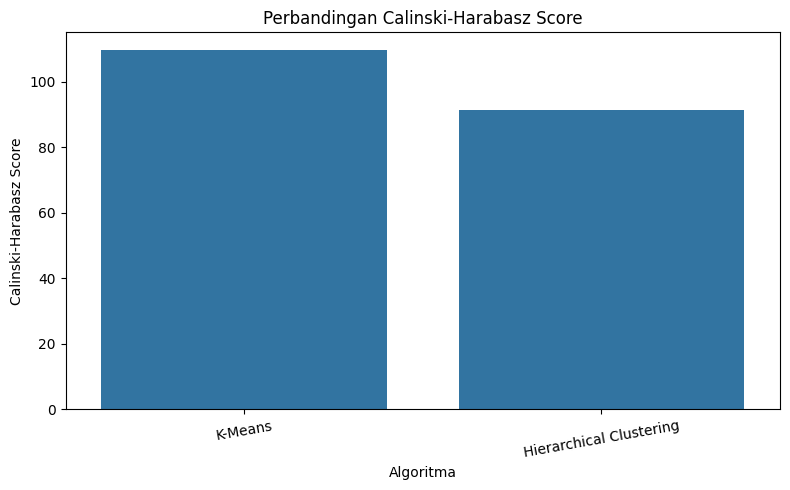

In [37]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=hasil_evaluasi,
    x='Algoritma',
    y='Calinski-Harabasz Score'
)

plt.title('Perbandingan Calinski-Harabasz Score')
plt.xlabel('Algoritma')
plt.ylabel('Calinski-Harabasz Score')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


### Kesimpulan hasil evaluasi

In [38]:
# Menghitung jumlah metrik yang dimenangkan

jumlah_kemenangan = {
    'K-Means': 0,
    'Hierarchical Clustering': 0
}

for pemenang in [
    best_silhouette,
    best_dbi,
    best_calinski
]:
    jumlah_kemenangan[pemenang] += 1

print("RINGKASAN HASIL EVALUASI")
print("=" * 45)

for algoritma, jumlah in jumlah_kemenangan.items():
    print(f"{algoritma}: {jumlah} dari 3 metrik")

if jumlah_kemenangan['K-Means'] > jumlah_kemenangan['Hierarchical Clustering']:
    print("\nK-Means unggul pada lebih banyak metrik evaluasi.")

elif jumlah_kemenangan['K-Means'] < jumlah_kemenangan['Hierarchical Clustering']:
    print("\nHierarchical Clustering unggul pada lebih banyak metrik.")

else:
    print("\nKedua algoritma memperoleh jumlah kemenangan metrik yang sama.")

print("\nCatatan: Kesimpulan akhir juga perlu mempertimbangkan")
print("karakteristik cluster dan hasil interpretasi masing-masing model.")


RINGKASAN HASIL EVALUASI
K-Means: 2 dari 3 metrik
Hierarchical Clustering: 1 dari 3 metrik

K-Means unggul pada lebih banyak metrik evaluasi.

Catatan: Kesimpulan akhir juga perlu mempertimbangkan
karakteristik cluster dan hasil interpretasi masing-masing model.


## Interpretasi

## Interpretasi Silhouette Score

Silhouette Score digunakan untuk mengukur seberapa baik suatu negara masuk ke dalam cluster yang sesuai berdasarkan kemiripannya dengan anggota cluster sendiri dan perbedaannya dengan cluster lain.
- K-Means memperoleh nilai 0,3372.
- Hierarchical memperoleh nilai 0,3178.
Interpretasi:

Berdasarkan hasil tersebut, K-Means memiliki nilai Silhouette Score lebih tinggi dibandingkan Hierarchical Clustering.

## interpretasi Davies-Bouldin Index (DBI)

DBI digunakan untuk mengukur tingkat kemiripan antarcluster. Semakin rendah nilainya, semakin baik hasil pengelompokannya.
- K-Means memperoleh nilai 1,1323.
- Hierarchical memperoleh nilai 1,1301.
Interpretasi:

Berdasarkan hasil evaluasi, Hierarchical Clustering memperoleh nilai DBI sedikit lebih rendah dibandingkan K-Means.

### Calinski-Harabasz Score

Calinski-Harabasz Score digunakan untuk mengukur perbandingan variasi antarcluster dengan variasi di dalam cluster. Semakin tinggi nilainya, semakin baik kualitas pengelompokan.
- K-Means memperoleh nilai 109,5408.
- Hierarchical memperoleh nilai 91,4753.
Interpretasi:

K-Means memperoleh nilai Calinski-Harabasz lebih tinggi dibandingkan Hierarchical Clustering.

### Interpretasi keseluruhan

Berdasarkan hasil evaluasi menggunakan tiga metrik, algoritma K-Means menunjukkan performa yang lebih baik dibandingkan Hierarchical Clustering.

K-Means unggul pada Silhouette Score dan Calinski-Harabasz Score, yang menunjukkan bahwa algoritma ini menghasilkan pemisahan kelompok negara yang relatif lebih baik.

Sementara itu, Hierarchical Clustering memperoleh nilai Davies-Bouldin Index yang sedikit lebih rendah, sehingga memiliki keunggulan tipis dalam aspek kekompakan dan pemisahan cluster berdasarkan metrik tersebut.

Dengan demikian, K-Means dipilih sebagai algoritma terbaik karena memperoleh hasil yang lebih unggul pada dua dari tiga metrik evaluasi.

## Praktikum 6 - Deployment

Pada tahap ini model K-Means terbaik disimpan bersama preprocessing yang telah di fit. Model dipilih karena unggul pada 2 dari 3 metrik evaluasi. Kemudian akan digunakan oleh aplikasi Streamlit untuk memprediksi cluster data negara baru.

## Memastikan variabel model tersedia

In [49]:
variabel_deployment = [
    'df',
    'X',
    'transformer',
    'scaler',
    'kmeans_final',
    'best_kmeans'
    ]
for nama in variabel_deployment:
    if nama not in globals():
        raise NameError(f'Variabel {nama} belum tersedia. Jalankan seluruh tahap Data Preparation dan Modeling terlebih dahulu.')

print('Semua variabel deployment tersedia.')
print('Jumlah cluster K-Means:', kmeans_final.n_clusters)
print('Fitur:', X.columns.tolist())

Semua variabel deployment tersedia.
Jumlah cluster K-Means: 2
Fitur: ['child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']


## Import library deployment

In [50]:
import joblib
import os
from pathlib import Path
import sklearn

print('Library deployment berhasil diimport.')

Library deployment berhasil diimport.


## Menghitung ulang metrik model final

In [51]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

label_deployment = kmeans_final.predict(scaler.transform(transformer.transform(X)))
metrics_deployment = {
    'silhouette': float(silhouette_score(scaler.transform(transformer.transform(X)), label_deployment)),
    'davies_bouldin': float(davies_bouldin_score(scaler.transform(transformer.transform(X)), label_deployment)),
    'calinski_harabasz': float(calinski_harabasz_score(scaler.transform(transformer.transform(X)), label_deployment))
}
print('Evaluasi model untuk deployment:')
for nama, nilai in metrics_deployment.items():
    print(f'{nama}: {nilai:.4f}')

Evaluasi model untuk deployment:
silhouette: 0.3372
davies_bouldin: 1.1323
calinski_harabasz: 109.5408


## Menyimpan model dan preprocessing dalam satu file

In [56]:
model_bundle = {
    'transformer': transformer,
    'scaler': scaler,
    'model': kmeans_final,
    'features': X.columns.tolist(),
    'metrics': metrics_deployment,
    'model_name': 'K-Means',
    'random_state': 42,
    'n_clusters': int(kmeans_final.n_clusters),
    'sklearn_version': sklearn.__version__
}

joblib.dump(model_bundle, 'country_clustering_model.joblib')
print('Model berhasil disimpan: country_clustering_model.joblib')
# Buat requirements dengan versi scikit-learn yang sama seperti lingkungan training
with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write('streamlit\npandas\nnumpy\njoblib\n')
    f.write(f'scikit-learn=={sklearn.__version__}\n')
print('requirements.txt dibuat dengan scikit-learn', sklearn.__version__)


Model berhasil disimpan: country_clustering_model.joblib
requirements.txt dibuat dengan scikit-learn 1.6.1


## Memuat ulang dan menguji model

In [57]:
bundle_test = joblib.load('country_clustering_model.joblib')
assert bundle_test['features'] == X.columns.tolist(), 'Urutan fitur tidak cocok!'

# Uji prediksi menggunakan satu baris data yang sudah ada
contoh_data = X.iloc[[0]].copy()
contoh_transform = bundle_test['transformer'].transform(contoh_data)
contoh_scaled = bundle_test['scaler'].transform(contoh_transform)
contoh_prediksi = bundle_test['model'].predict(contoh_scaled)

print('Uji artefak berhasil.')
print('Negara:', df.iloc[0]['country'])
print('Prediksi cluster:', int(contoh_prediksi[0]))

Uji artefak berhasil.
Negara: Afghanistan
Prediksi cluster: 1


## Mengundul model untuk aplikasi Streamlit

In [58]:
from google.colab import files
files.download('country_clustering_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Melihat jumlah anggota dan karakteristik setiap cluster

In [59]:
# Membuat label cluster dari model final pada data yang sama dengan proses training
X_deployment_scaled = scaler.transform(transformer.transform(X))
label_profil = kmeans_final.predict(X_deployment_scaled)

# Menggabungkan identitas negara, fitur asli, dan label cluster
data_profil_cluster = X.copy()
data_profil_cluster['country'] = df['country'].values
data_profil_cluster['cluster'] = label_profil

# Menghitung jumlah negara dan rata-rata setiap fitur pada masing-masing cluster
jumlah_anggota_cluster = (
    data_profil_cluster.groupby('cluster')['country']
    .count()
    .rename('jumlah_negara')
)

profil_rata_rata_cluster = data_profil_cluster.groupby('cluster')[X.columns].mean()
profil_cluster = jumlah_anggota_cluster.to_frame().join(profil_rata_rata_cluster)

print('JUMLAH ANGGOTA DAN PROFIL RATA-RATA CLUSTER')
display(profil_cluster.round(2))

print('DAFTAR NEGARA PADA SETIAP CLUSTER')
for cluster_id in sorted(data_profil_cluster['cluster'].unique()):
    daftar_negara = data_profil_cluster.loc[
        data_profil_cluster['cluster'] == cluster_id, 'country'
    ].tolist()
    print(f'\\nCluster {cluster_id} ({len(daftar_negara)} negara):')
    print(', '.join(daftar_negara))

JUMLAH ANGGOTA DAN PROFIL RATA-RATA CLUSTER


,jumlah_negara,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,,,
0,94,11.34,49.22,7.47,48.9,27032.98,5.43,76.76,1.91,21441.6
1,73,72.95,30.66,5.98,44.3,4411.82,10.81,62.57,4.28,2048.0


DAFTAR NEGARA PADA SETIAP CLUSTER
\nCluster 0 (94 negara):
Albania, Algeria, Antigua and Barbuda, Argentina, Armenia, Australia, Austria, Azerbaijan, Bahamas, Bahrain, Barbados, Belarus, Belgium, Belize, Bosnia and Herzegovina, Brazil, Brunei, Bulgaria, Canada, Chile, China, Colombia, Costa Rica, Croatia, Cyprus, Czech Republic, Denmark, Dominican Republic, Ecuador, El Salvador, Estonia, Finland, France, Georgia, Germany, Greece, Grenada, Hungary, Iceland, Iran, Ireland, Israel, Italy, Jamaica, Japan, Jordan, Kazakhstan, Kuwait, Latvia, Lebanon, Libya, Lithuania, Luxembourg, Macedonia, FYR, Malaysia, Maldives, Malta, Mauritius, Moldova, Montenegro, Netherlands, New Zealand, Norway, Oman, Panama, Paraguay, Peru, Poland, Portugal, Qatar, Romania, Russia, Saudi Arabia, Serbia, Seychelles, Singapore, Slovak Republic, Slovenia, South Korea, Spain, St. Vincent and the Grenadines, Suriname, Sweden, Switzerland, Thailand, Tunisia, Turkey, Ukraine, United Arab Emirates, United Kingdom, United S